# StreamVault licensing analysis: franchise bundles vs standalone hits

**Runs top to bottom with no edits** (Run All). It reuses the saved TMDb replies in `data/raw/`, so it works without an API key and gives identical results each time. To pull fresh data first, run `src/fetch.py --refresh` (needs a key in `.env`).

All logic lives in `src/` so it can also run from the command line (`src/run_all.py`). This notebook calls it, shows the results, and checks them.

| Section | Answers |
|---|---|
| 1. Acquisition | Every id in `id_list.csv` accounted for |
| 2. Tables and join proof | Nested JSON flattened, and no film dropped or duplicated |
| 3. Diagnosis | How much each data problem moves the answer |
| 4. Franchise vs standalone | Both windows, with uncertainty, and a loud flag if they disagree |
| 5. Weak later entries | Does a series get weaker as it goes on? |
| 6. Bundles | Each scored on the films offered and on the whole released series |
| 7. Shortlist | 3 bundles and 5 standalones, each with its reason |
| 8. Talent | Directors and lead actors who signal a strong title |
| 9. Deal note numbers | The strongest bundle, priced relative to everything else |
| 10. Run time | Measured against the time budget |

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import fetch, build_tables, diagnose, analysis, metrics

pd.set_option("display.max_colwidth", 160, "display.width", 200)
NOTEBOOK_START = time.perf_counter()
FRANCHISE_COLOR, STANDALONE_COLOR = "#2a78d6", "#eb6834"   # validated categorical pair (slots 1 and 2)

## 1. Acquisition: every id accounted for

In [2]:
t0 = time.perf_counter()
exit_code = fetch.main([])          # reuses saved replies; downloads only what is missing
assert exit_code == 0
acquire_seconds = time.perf_counter() - t0

audit = pd.read_csv(ROOT / "data/processed/id_audit.csv", dtype={"raw_value": str}, keep_default_na=False)
raw_lines = (ROOT / "data/id_list.csv").read_text(encoding="utf-8").splitlines()
fates = audit["fate"].value_counts()
display(fates.rename("rows").to_frame())
assert len(audit) == len(raw_lines) - 1, "a row of the input file is missing from the audit"
assert fates.sum() == len(audit), "every row must have exactly one fate"
print(f"Input rows: {len(raw_lines) - 1}  |  accounted for: {fates.sum()}  |  in the analysis: {fates['fetched']}")

Read 127 rows from id_list.csv
kind
tmdb_id         123
non_positive      1
blank             1
imdb_id           1
not_an_id         1 

  IMDb id tt0468569 -> TMDb id 155 (The Dark Knight)

Unique usable TMDb ids to fetch: 117

  20/117 ids done (0 network calls so far)
  40/117 ids done (0 network calls so far)
  60/117 ids done (0 network calls so far)
  80/117 ids done (0 network calls so far)
  100/117 ids done (0 network calls so far)
  117/117 ids done (0 network calls so far)
  32 franchises (collections) checked
  39 released franchise films not on the list checked

=== Reconciliation: fate of every row in the input file ===
fate
fetched              112
duplicate              7
not_found_on_tmdb      5
non_positive           1
blank                  1
not_an_id              1
TOTAL                     127  (input rows: 127)

Network calls this run: 0   Re-used from disk: 305   Time: 0.2s

Wrote data/processed/id_audit.csv and data/processed/fetch_log.csv


,rows
fate,
fetched,112
duplicate,7
not_found_on_tmdb,5
non_positive,1
blank,1
not_an_id,1


Input rows: 127  |  accounted for: 127  |  in the analysis: 112


In [3]:
# The rows that did NOT reach the analysis, and why
audit.loc[audit["fate"] != "fetched", ["row_number", "raw_value", "tmdb_id", "fate"]]

,row_number,raw_value,tmdb_id,fate
16,18,8471293,8471293,not_found_on_tmdb
28,30,-1,,non_positive
33,35,9412887,9412887,not_found_on_tmdb
41,43,603,603,duplicate
58,60,278,278,duplicate
67,69,,,blank
71,73,8471294,8471294,not_found_on_tmdb
88,90,1891,1891,duplicate
89,91,155,155,duplicate
91,93,9412888,9412888,not_found_on_tmdb


## 2. From nested JSON to tables, and proof the joins are safe

In [4]:
tables = build_tables.build_all(save=True)   # contains assert-based join checks
films, people, coll = tables["films"], tables["people"], tables["collections"]

# Explicit proof, shown rather than assumed:
checks = pd.DataFrame([
    ("films: one row per film (tmdb_id unique)", films["tmdb_id"].is_unique),
    ("films == the ids fetched in the audit", set(films["tmdb_id"]) == set(audit.loc[audit["fate"].eq("fetched"), "tmdb_id"].astype(float).astype(int))),
    ("people -> films join keeps row count", len(people.merge(films[["tmdb_id"]], on="tmdb_id", validate="many_to_one")) == len(people)),
    ("films -> franchises join keeps row count", len(films.merge(coll[["collection_id"]], on="collection_id", how="left", validate="many_to_one")) == len(films)),
    ("every franchise film finds its franchise", films["collection_id"].dropna().isin(coll["collection_id"]).all()),
], columns=["check", "passed"])
display(checks)
assert checks["passed"].all()
print(f"films: {len(films)} rows | film_people: {len(people)} rows | franchises: {len(coll)} | off-list franchise films: {len(tables['films_extra'])}")

,check,passed
0,films: one row per film (tmdb_id unique),True
1,films == the ids fetched in the audit,True
2,people -> films join keeps row count,True
3,films -> franchises join keeps row count,True
4,every franchise film finds its franchise,True


films: 112 rows | film_people: 458 rows | franchises: 32 | off-list franchise films: 39


In [5]:
films[["tmdb_id", "title", "year", "budget", "revenue", "vote_average", "vote_count", "collection_name"]].head()

,tmdb_id,title,year,budget,revenue,vote_average,vote_count,collection_name
0,11,Star Wars,1977,11000000.0,7.753980e+08,8.206,23191,Star Wars Collection
1,13,Forrest Gump,1994,55000000.0,6.773877e+08,8.462,30919,NaN
2,22,Pirates of the Caribbean: The Curse of the Black Pearl,2003,140000000.0,6.550112e+08,7.838,23122,Pirates of the Caribbean Collection
3,24,Kill Bill: Vol. 1,2003,30000000.0,1.809061e+08,7.970,19751,Kill Bill Collection
4,58,Pirates of the Caribbean: Dead Man's Chest,2006,200000000.0,1.066180e+09,7.393,17868,Pirates of the Caribbean Collection


## 3. Diagnosis: how much does each problem move the answer?

Headline = franchise minus standalone, using medians. Each scenario leaves one problem **unhandled**. The full write-up is in `data_findings.md`.

In [6]:
effects = diagnose.run_effects(tables)
cols = ["scenario", "window", "franchise_n", "standalone_n", "franchise_multiple", "standalone_multiple",
        "multiple_gap", "franchise_rating", "standalone_rating", "rating_gap", "multiple_leader"]
effects[cols].round(2)

,scenario,window,franchise_n,standalone_n,franchise_multiple,standalone_multiple,multiple_gap,franchise_rating,standalone_rating,rating_gap,multiple_leader
0,baseline,all_years,87,25,5.53,5.00,0.53,7.49,8.21,-0.72,franchise
1,baseline,2000_onward,59,12,5.05,4.49,0.56,7.39,8.14,-0.75,franchise
2,duplicates left in,all_years,91,28,5.53,4.76,0.76,7.58,8.30,-0.72,franchise
3,duplicates left in,2000_onward,61,12,5.07,4.49,0.58,7.45,8.14,-0.69,franchise
4,franchise = any series (TMDb flag),all_years,96,16,5.62,3.84,1.78,7.60,8.44,-0.84,franchise
5,franchise = any series (TMDb flag),2000_onward,63,8,5.05,3.84,1.21,7.45,8.19,-0.74,franchise
6,averages instead of medians,all_years,87,25,7.94,10.48,-2.54,7.44,8.10,-0.66,standalone
7,averages instead of medians,2000_onward,59,12,5.45,4.89,0.55,7.33,7.92,-0.59,franchise
8,bundles include their off-list films,all_years,107,25,5.08,5.00,0.08,7.39,8.21,-0.82,franchise
9,bundles include their off-list films,2000_onward,79,12,4.59,4.49,0.10,7.28,8.14,-0.87,franchise


## 4. Franchise vs standalone, in both windows

Each film gets a **title score** from 0 to 100: the average of three percentile ranks against the other films in the same window. The three are audience **rating** (quality), **number of audience ratings** (reach), and **box-office multiple** (revenue ÷ budget). The 95% range comes from 10,000 resamples.

In [7]:
data = analysis.load(tables)
results = analysis.run(data)
analysis.save(results)

rows = []
for w in analysis.WINDOWS:
    r = results[w]; g = r["gap"]; c = r["comparison"]
    rows.append({"window": w, "franchise films": c.loc["franchise", "films"], "standalone films": c.loc["standalone", "films"],
                 "franchise median score": c.loc["franchise", "median_title_score"],
                 "standalone median score": c.loc["standalone", "median_title_score"],
                 "gap": g["gap"], "95% low": g["low"], "95% high": g["high"], "verdict": r["verdict"]})
summary = pd.DataFrame(rows).set_index("window")
display(summary.round(1))
for w in analysis.WINDOWS:
    print(w); display(results[w]["comparison"].round(2))

,franchise films,standalone films,franchise median score,standalone median score,gap,95% low,95% high,verdict
window,,,,,,,,
all_years,87,25,46.6,59.5,-12.9,-27.4,-0.3,standalone
2000_onward,59,12,47.7,56.6,-8.9,-26.3,3.3,too close to call


all_years


,films,median_title_score,median_rating,median_audience_ratings,median_box_office_multiple
group,,,,,
franchise,87,46.58,7.49,15452.0,5.53
standalone,25,59.52,8.21,18876.0,5.00


2000_onward


,films,median_title_score,median_rating,median_audience_ratings,median_box_office_multiple
group,,,,,
franchise,59,47.65,7.39,15695.0,5.05
standalone,12,56.57,8.14,19401.0,4.49


In [8]:
if results["verdict_changes_between_windows"]:
    display(Markdown(
        "## ⚠️ THE ANSWER CHANGES BETWEEN THE TWO WINDOWS\n\n"
        f"**All years: {results['all_years']['verdict'].upper()}.** "
        f"**2000 onward: {results['2000_onward']['verdict'].upper()}.**\n\n"
        "Standalones still score higher from 2000 onward, but with only "
        f"{int(summary.loc['2000_onward', 'standalone films'])} standalones the 95% range of the gap crosses zero. "
        "The memo must say this plainly."))
else:
    display(Markdown(f"**Same verdict in both windows: {results['all_years']['verdict'].upper()}.**"))

## ⚠️ THE ANSWER CHANGES BETWEEN THE TWO WINDOWS

**All years: STANDALONE.** **2000 onward: TOO CLOSE TO CALL.**

Standalones still score higher from 2000 onward, but with only 12 standalones the 95% range of the gap crosses zero. The memo must say this plainly.

## 5. Do later entries in a series score lower?

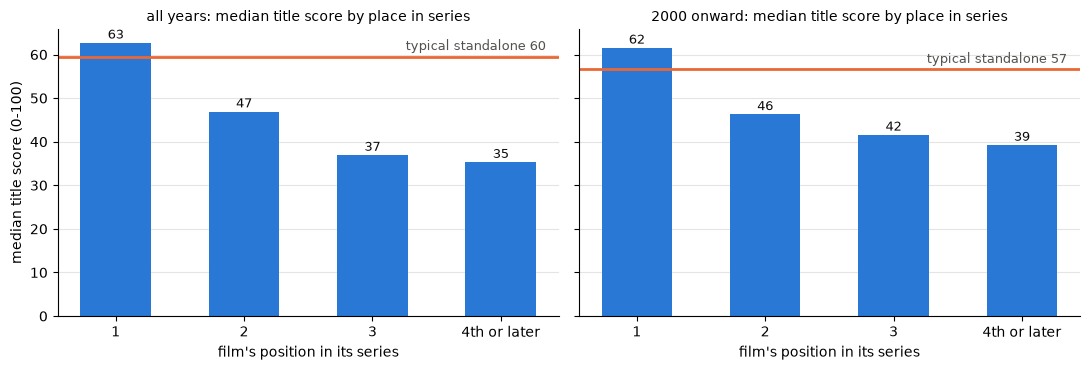

all_years


,films,median_title_score,median_rating,median_box_office_multiple,share_below_typical_standalone
position_label,,,,,
1,23,62.65,7.90,7.36,0.43
2,23,46.88,7.39,5.53,0.78
3,22,36.90,7.32,4.69,0.82
4th or later,19,35.27,7.12,4.56,0.79


2000_onward


,films,median_title_score,median_rating,median_box_office_multiple,share_below_typical_standalone
position_label,,,,,
1,12,61.50,7.77,5.67,0.42
2,14,46.24,7.34,5.20,0.64
3,16,41.55,7.11,4.69,0.62
4th or later,17,39.20,7.23,4.56,0.71


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, w in zip(axes, analysis.WINDOWS):
    pos = results[w]["positions"]
    films_w = results[w]["films"]
    typical = films_w.loc[films_w["group"].eq("standalone"), "title_score"].median()
    ax.bar(pos.index, pos["median_title_score"], color=FRANCHISE_COLOR, width=0.55)
    ax.axhline(typical, color=STANDALONE_COLOR, linewidth=2)
    ax.text(3.35, typical + 1.5, f"typical standalone {typical:.0f}", ha="right", color="#52514e", fontsize=9)
    for x, v in enumerate(pos["median_title_score"]):
        ax.text(x, v + 1, f"{v:.0f}", ha="center", fontsize=9, color="#0b0b0b")
    ax.set_title(f"{w.replace('_', ' ')}: median title score by place in series", fontsize=10)
    ax.set_xlabel("film's position in its series"); ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("median title score (0-100)")
plt.tight_layout(); plt.show()
for w in analysis.WINDOWS:
    print(w); display(results[w]["positions"].round(2))

## 6. Bundles: the films offered vs the whole released series

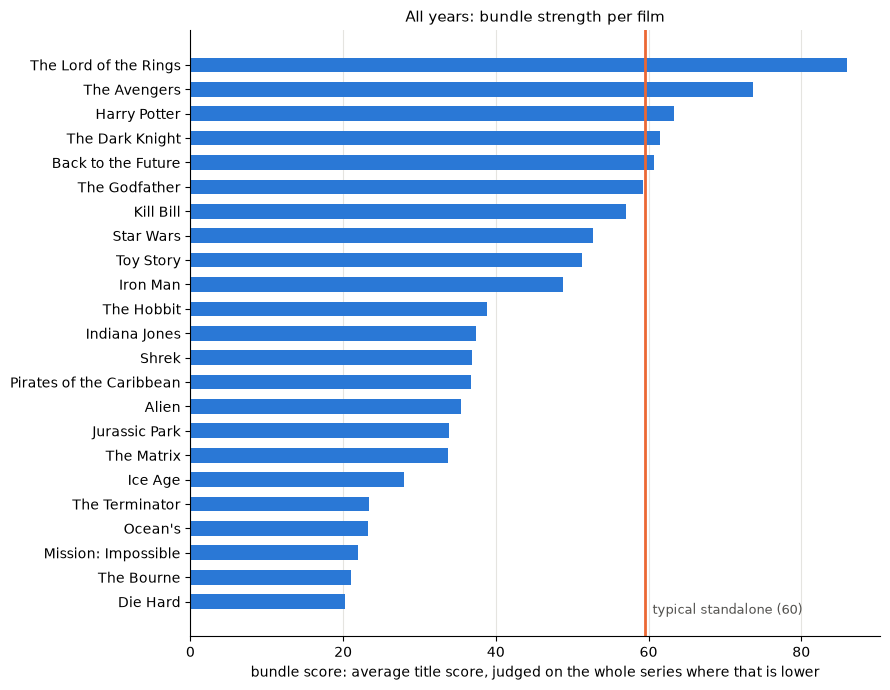

,collection_name,films_on_list,films_whole_series,mean_score_on_list,mean_score_whole_series,bundle_score,weakest_film,weakest_title,value_per_film_vs_typical_standalone
0,The Lord of the Rings Collection,3,3,86.01,86.01,86.01,84.52,The Lord of the Rings: The Fellowship of the Ring,1.44
1,The Avengers Collection,4,4,73.66,73.66,73.66,55.80,Avengers: Age of Ultron,1.24
2,Harry Potter Collection,8,8,63.32,63.32,63.32,47.77,Harry Potter and the Half-Blood Prince,1.06
3,The Dark Knight Collection,3,3,61.56,61.56,61.56,46.28,Batman Begins,1.03
4,Back to the Future Collection,3,3,60.66,60.66,60.66,43.30,Back to the Future Part III,1.02
5,The Godfather Collection,3,3,59.28,59.28,59.28,16.82,The Godfather Part III,1.00
6,Kill Bill Collection,2,2,57.07,57.07,57.07,51.64,Kill Bill: Vol. 2,0.96
7,Star Wars Collection,6,9,61.66,52.68,52.68,13.10,Star Wars: The Rise of Skywalker,0.88
8,Toy Story Collection,4,5,54.13,51.22,51.22,39.58,Toy Story 5,0.86
9,Iron Man Collection,3,3,48.86,48.86,48.86,37.95,Iron Man 2,0.82


In [10]:
b = results["all_years"]["bundles"]
fig, ax = plt.subplots(figsize=(9, 7))
typical = results["all_years"]["films"].query("group == 'standalone'")["title_score"].median()
names = b["collection_name"].str.replace(" Collection", "")
ax.barh(names, b["bundle_score"], color=FRANCHISE_COLOR, height=0.6)
ax.axvline(typical, color=STANDALONE_COLOR, linewidth=2)
ax.text(typical + 1, len(b) - 0.5, f"typical standalone ({typical:.0f})", color="#52514e", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("bundle score: average title score, judged on the whole series where that is lower")
ax.set_title("All years: bundle strength per film", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e5e4e0", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
cols = ["collection_name", "films_on_list", "films_whole_series", "mean_score_on_list", "mean_score_whole_series",
        "bundle_score", "weakest_film", "weakest_title", "value_per_film_vs_typical_standalone"]
b[cols].round(2)

In [11]:
results["2000_onward"]["bundles"][cols].round(2)

,collection_name,films_on_list,films_whole_series,mean_score_on_list,mean_score_whole_series,bundle_score,weakest_film,weakest_title,value_per_film_vs_typical_standalone
0,The Lord of the Rings Collection,3,3,91.94,91.94,91.94,90.38,The Lord of the Rings: The Two Towers,1.63
1,The Avengers Collection,4,4,81.22,81.22,81.22,61.74,Avengers: Age of Ultron,1.44
2,Harry Potter Collection,8,8,69.01,69.01,69.01,50.00,Harry Potter and the Half-Blood Prince,1.22
3,The Dark Knight Collection,3,3,65.10,65.10,65.10,47.65,Batman Begins,1.15
4,Kill Bill Collection,2,2,62.44,62.44,62.44,57.04,Kill Bill: Vol. 2,1.10
5,Iron Man Collection,3,3,52.35,52.35,52.35,38.26,Iron Man 2,0.93
6,Toy Story Collection,2,3,53.76,50.86,50.86,45.07,Toy Story 5,0.90
7,Shrek Collection,4,4,42.14,42.14,42.14,22.77,Shrek Forever After,0.74
8,Star Wars Collection,2,5,48.83,41.97,41.97,13.62,Star Wars: The Rise of Skywalker,0.74
9,The Hobbit Collection,3,3,41.08,41.08,41.08,37.79,The Hobbit: The Battle of the Five Armies,0.73


## 7. Shortlist: 3 bundles and 5 standalones, each with its reason

In [12]:
for w in analysis.WINDOWS:
    display(Markdown(f"### {w.replace('_', ' ')}"))
    display(results[w]["franchise_picks"][["collection_name", "bundle_score", "reason"]].round(1))
    display(results[w]["standalone_picks"].round(1))

### all years

,collection_name,bundle_score,reason
0,The Lord of the Rings Collection,86.0,3 films; average title score 86/100 (1.44x a typical standalone per film); weakest film 'The Lord of the Rings: The Fellowship of the Ring' scores 85
1,The Avengers Collection,73.7,4 films; average title score 74/100 (1.24x a typical standalone per film); weakest film 'Avengers: Age of Ultron' scores 56
2,Harry Potter Collection,63.3,8 films; average title score 63/100 (1.06x a typical standalone per film); weakest film 'Harry Potter and the Half-Blood Prince' scores 48


,tmdb_id,title,year,title_score,vote_average,vote_count,box_office_multiple,reason
57,680,Pulp Fiction,1994,93.3,8.5,31365,26.7,"rating 8.5 (top 8%), 31,365 audience ratings (top 7%), earned 26.7x its budget (top 5%); released before 2000"
1,13,Forrest Gump,1994,89.7,8.5,30919,12.3,"rating 8.5 (top 9%), 30,919 audience ratings (top 8%), earned 12.3x its budget (top 14%); released before 2000"
15,129,Spirited Away,2001,82.6,8.5,19245,14.5,"rating 8.5 (top 4%), 19,245 audience ratings (top 37%), earned 14.5x its budget (top 11%)"
38,424,Schindler's List,1993,81.7,8.6,18205,14.6,"rating 8.6 (top 3%), 18,205 audience ratings (top 42%), earned 14.6x its budget (top 10%); released before 2000"
96,27205,Inception,2010,76.9,8.4,40769,5.2,"rating 8.4 (top 15%), 40,769 audience ratings (top 1%), earned 5.2x its budget (top 53%)"


### 2000 onward

,collection_name,bundle_score,reason
0,The Lord of the Rings Collection,91.9,3 films; average title score 92/100 (1.63x a typical standalone per film); weakest film 'The Lord of the Rings: The Two Towers' scores 90
1,The Avengers Collection,81.2,4 films; average title score 81/100 (1.44x a typical standalone per film); weakest film 'Avengers: Age of Ultron' scores 62
2,Harry Potter Collection,69.0,8 films; average title score 69/100 (1.22x a typical standalone per film); weakest film 'Harry Potter and the Half-Blood Prince' scores 50


,tmdb_id,title,year,title_score,vote_average,vote_count,box_office_multiple,reason
15,129,Spirited Away,2001,84.7,8.5,19245,14.5,"rating 8.5 (top 1%), 19,245 audience ratings (top 44%), earned 14.5x its budget (top 1%)"
96,27205,Inception,2010,81.9,8.4,40769,5.2,"rating 8.4 (top 9%), 40,769 audience ratings (top 2%), earned 5.2x its budget (top 43%)"
106,157336,Interstellar,2014,79.3,8.5,41950,4.5,"rating 8.5 (top 4%), 41,950 audience ratings (top 1%), earned 4.5x its budget (top 57%)"
5,77,Memento,2000,59.4,8.2,17065,4.5,"rating 8.2 (top 15%), 17,065 audience ratings (top 49%), earned 4.5x its budget (top 58%)"
92,10681,WALL·E,2008,53.8,8.1,21213,2.9,"rating 8.1 (top 18%), 21,213 audience ratings (top 35%), earned 2.9x its budget (top 87%)"


## 8. Talent: who reliably signals a title worth licensing?

Each franchise counts **once** per person, so eight Harry Potter films are one result, not eight. To appear, a person needs at least two separate results. **Lift** is their average score minus the typical title's score.

In [13]:
for w in analysis.WINDOWS:
    display(Markdown(f"### {w.replace('_', ' ')}"))
    t = results[w]["talent"]
    display(t.groupby("role").head(8)[["role", "person_name", "separate_results", "films", "average_score",
                                       "hit_rate", "lift_vs_typical", "evidence", "titles"]].round(2))

### all years

,role,person_name,separate_results,films,average_score,hit_rate,lift_vs_typical,evidence,titles
0,director,Robert Zemeckis,2,4,75.20,1.00,25.50,thin (2 results),Back to the Future; Forrest Gump
1,director,Quentin Tarantino,2,3,75.19,1.00,25.48,thin (2 results),Kill Bill: Vol. 1; Pulp Fiction
2,director,Christopher Nolan,5,7,64.10,1.00,14.39,moderate,The Dark Knight; The Prestige; Interstellar; Inception
3,director,Peter Jackson,2,6,62.43,0.50,12.72,thin (2 results),The Lord of the Rings: The Fellowship of the Ring; The Hobbit: An Unexpected Journey
4,director,Steven Spielberg,4,8,60.04,0.75,10.34,moderate,Jaws; Jurassic Park; Raiders of the Lost Ark; Schindler's List
5,director,James Cameron,2,3,57.92,1.00,8.22,thin (2 results),The Terminator; Aliens
6,director,Ridley Scott,2,2,54.02,0.50,4.32,thin (2 results),Blade Runner; Alien
7,director,Martin Scorsese,2,2,47.40,0.00,-2.31,thin (2 results),The Departed; GoodFellas
11,lead_actor,Uma Thurman,2,3,75.19,1.00,25.48,thin (2 results),Kill Bill: Vol. 1; Pulp Fiction
12,lead_actor,Tom Hanks,2,5,71.93,1.00,22.23,thin (2 results),Toy Story; Forrest Gump


### 2000 onward

,role,person_name,separate_results,films,average_score,hit_rate,lift_vs_typical,evidence,titles
0,director,Christopher Nolan,5,7,67.25,1.00,17.25,moderate,The Dark Knight; The Prestige; Interstellar; Inception
1,director,Peter Jackson,2,6,66.51,0.50,16.51,thin (2 results),The Lord of the Rings: The Fellowship of the Ring; The Hobbit: An Unexpected Journey
2,director,Brad Bird,2,2,50.70,0.50,0.70,thin (2 results),The Incredibles; Mission: Impossible - Ghost Protocol
3,lead_actor,Robert Downey Jr.,2,7,66.78,1.00,16.78,thin (2 results),Iron Man; The Avengers
4,lead_actor,Ian McKellen,2,6,66.51,0.50,16.51,thin (2 results),The Lord of the Rings: The Fellowship of the Ring; The Hobbit: An Unexpected Journey
5,lead_actor,Leonardo DiCaprio,2,2,66.20,1.00,16.20,thin (2 results),The Departed; Inception
6,lead_actor,Michael Caine,3,3,59.15,0.67,9.15,moderate,Batman Begins; The Prestige; Interstellar
7,lead_actor,Tom Hardy,2,2,54.69,0.50,4.69,thin (2 results),The Dark Knight Rises; Mad Max: Fury Road
8,lead_actor,Carrie-Anne Moss,2,3,44.13,0.50,-5.87,thin (2 results),The Matrix Reloaded; Memento
9,lead_actor,Matt Damon,2,4,42.88,0.50,-7.12,thin (2 results),The Bourne Identity; The Departed


## 9. Deal note numbers: the strongest bundle

In [14]:
pd.DataFrame({w: results[w]["deal"] for w in analysis.WINDOWS})

,all_years,2000_onward
bundle,The Lord of the Rings Collection,The Lord of the Rings Collection
films,3,3
complete,True,True
bundle_score,86.011905,91.940532
value_per_film_vs_typical_standalone,1.445,1.625173
value_per_film_vs_typical_bundle,2.300955,2.190529
value_per_film_vs_next_best_bundle,1.167677,1.131985
next_best_bundle,The Avengers Collection,The Avengers Collection
weakest_title,The Lord of the Rings: The Fellowship of the Ring,The Lord of the Rings: The Two Towers
weakest_film_score,84.52381,90.375587


## 10. Run time

Target: a full rerun from saved data in **under 60 seconds** on a laptop, so Adjoa can run it live in a meeting. Repeated, fresh-process and 560-film measurements are in `reports/runtime_report.md` (`src/benchmark.py`).

In [15]:
total = time.perf_counter() - NOTEBOOK_START
print(f"Acquisition step (saved data): {acquire_seconds:.2f}s")
print(f"Whole notebook, top to bottom: {total:.2f}s  -> target 60s met: {total < 60}")

Acquisition step (saved data): 0.19s
Whole notebook, top to bottom: 1.92s  -> target 60s met: True
